# Feature Engineering for UFC Predictions

**Converted from Rmd to Python/Jupyter**  
Original author: Abtin Olaee

This notebook is a Python translation of the R Markdown workflow. It uses the actual column names from the UFC dataset version with names such as `B_fighter`, `R_fighter`, `B_age`, and `R_age`.

In [17]:
# Core libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Interactive display
from IPython.display import display

# Machine learning
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

np.random.seed(123)
RANDOM_STATE = 123

csv_file = "./ufc-clean.csv"
ufc = pd.read_csv(csv_file)

print(ufc.shape)
display(pd.DataFrame({"Column_Names": ufc.columns}))

(7169, 51)


,Column_Names
0,date
1,R_fighter
2,B_fighter
3,Winner
4,finish
5,title_bout
6,weight_class
7,gender
8,no_of_rounds
9,R_current_lose_streak


## Introduction

Mixed martial arts has become the most electric and fastest growing sport of the last decade. The UFC is the leading mixed martial arts organization, making it a practical dataset source for building fight prediction models.

The dataset used here comes from the Kaggle Ultimate UFC Dataset. After conducting a preliminary analysis, the dataset contains thousands of observations and many variables. The number of observations is manageable, but the large number of variables must be filtered before predictive modeling.

## Explanatory Data Analysis

First, we inspect whether age, reach, and height differences appear to separate winners from losers.

### Age Distribution of Winners vs Losers

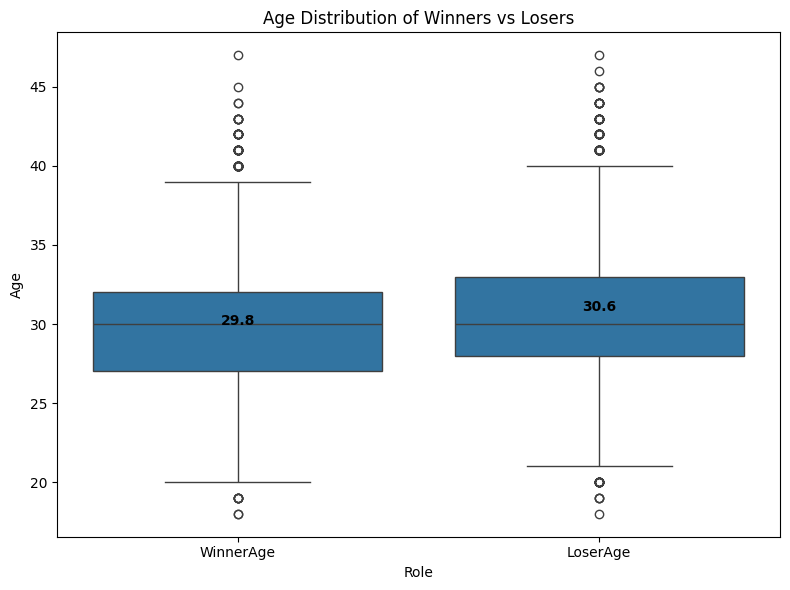

In [18]:
ufc_age = ufc.assign(
    WinnerAge=np.where(ufc["Winner"].eq("Blue"), ufc["B_age"], ufc["R_age"]),
    LoserAge=np.where(ufc["Winner"].eq("Blue"), ufc["R_age"], ufc["B_age"])
)

ufc_age = ufc_age.melt(
    value_vars=["WinnerAge", "LoserAge"],
    var_name="Role",
    value_name="Age"
)

plt.figure(figsize=(8, 6))
sns.boxplot(data=ufc_age, x="Role", y="Age")

means = ufc_age.groupby("Role")["Age"].mean()
for i, role in enumerate(["WinnerAge", "LoserAge"]):
    plt.text(i, means.loc[role], round(means.loc[role], 1), ha="center", va="bottom", fontweight="bold")

plt.title("Age Distribution of Winners vs Losers")
plt.xlabel("Role")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

### Reach Distribution of Winners vs Losers

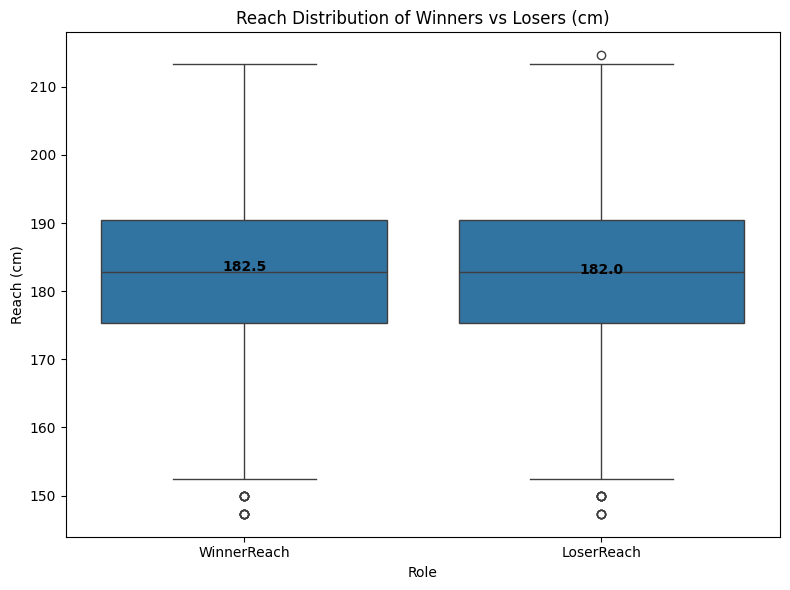

In [19]:
ufc_reach = ufc.assign(
    WinnerReach=np.where(ufc["Winner"].eq("Blue"), ufc["B_Reach_cms"], ufc["R_Reach_cms"]),
    LoserReach=np.where(ufc["Winner"].eq("Blue"), ufc["R_Reach_cms"], ufc["B_Reach_cms"])
)

ufc_reach = ufc_reach.melt(
    value_vars=["WinnerReach", "LoserReach"],
    var_name="Role",
    value_name="Reach"
)
ufc_reach = ufc_reach[ufc_reach["Reach"] != 0]

plt.figure(figsize=(8, 6))
sns.boxplot(data=ufc_reach, x="Role", y="Reach")

means = ufc_reach.groupby("Role")["Reach"].mean()
for i, role in enumerate(["WinnerReach", "LoserReach"]):
    plt.text(i, means.loc[role], round(means.loc[role], 1), ha="center", va="bottom", fontweight="bold")

plt.title("Reach Distribution of Winners vs Losers (cm)")
plt.xlabel("Role")
plt.ylabel("Reach (cm)")
plt.tight_layout()
plt.show()

### Height Distribution of Winners vs Losers

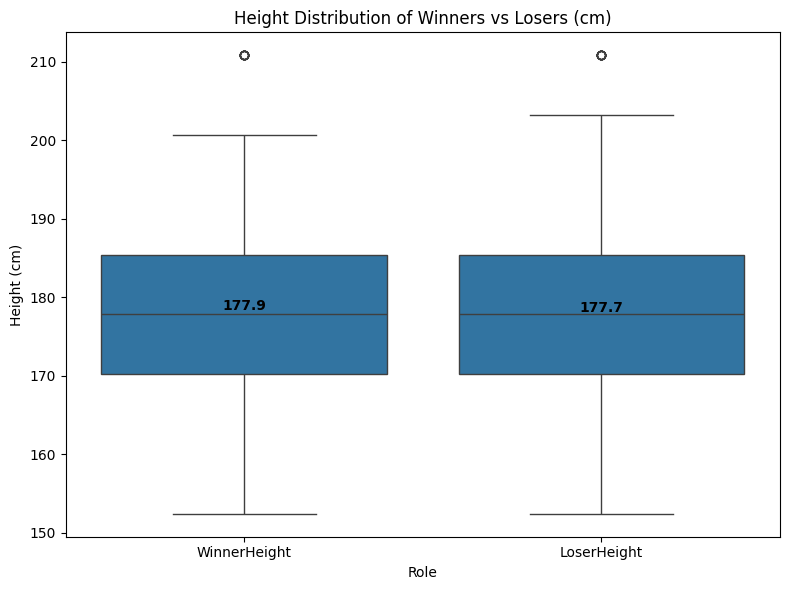

In [20]:
ufc_height = ufc.assign(
    WinnerHeight=np.where(ufc["Winner"].eq("Blue"), ufc["B_Height_cms"], ufc["R_Height_cms"]),
    LoserHeight=np.where(ufc["Winner"].eq("Blue"), ufc["R_Height_cms"], ufc["B_Height_cms"])
)

ufc_height = ufc_height.melt(
    value_vars=["WinnerHeight", "LoserHeight"],
    var_name="Role",
    value_name="Height"
)
ufc_height = ufc_height[ufc_height["Height"] != 0]

plt.figure(figsize=(8, 6))
sns.boxplot(data=ufc_height, x="Role", y="Height")

means = ufc_height.groupby("Role")["Height"].mean()
for i, role in enumerate(["WinnerHeight", "LoserHeight"]):
    plt.text(i, means.loc[role], round(means.loc[role], 1), ha="center", va="bottom", fontweight="bold")

plt.title("Height Distribution of Winners vs Losers (cm)")
plt.xlabel("Role")
plt.ylabel("Height (cm)")
plt.tight_layout()
plt.show()

## Fighter Style Clustering

The next feature engineering step creates fighter style clusters. The idea is to convert each fighter's historical technical profile into a categorical style feature.

In [21]:
# Fighter style clustering without modifying original ufc dataframe

# Columns used only for style clustering
red_style_cols = [
    "R_avg_SIG_STR_landed",
    "R_avg_SIG_STR_pct",
    "R_avg_SUB_ATT",
    "R_avg_TD_landed",
    "R_avg_TD_pct",
    "R_Height_cms",
    "R_Reach_cms",
    "R_Weight_lbs",
    "R_win_by_Decision",
    "R_win_by_KO_TKO",
    "R_win_by_Submission"
]

blue_style_cols = [
    "B_avg_SIG_STR_landed",
    "B_avg_SIG_STR_pct",
    "B_avg_SUB_ATT",
    "B_avg_TD_landed",
    "B_avg_TD_pct",
    "B_Height_cms",
    "B_Reach_cms",
    "B_Weight_lbs",
    "B_win_by_Decision",
    "B_win_by_KO_TKO",
    "B_win_by_Submission"
]

# Shared clustering feature names
# These are temporary names only for the fighter-level clustering table.
style_base_cols = [
    "avg_SIG_STR_landed",
    "avg_SIG_STR_pct",
    "avg_SUB_ATT",
    "avg_TD_landed",
    "avg_TD_pct",
    "Height_cms",
    "Reach_cms",
    "Weight_lbs",
    "win_by_Decision",
    "win_by_KO_TKO",
    "win_by_Submission"
]

# Build red fighter style table
red_style_data = ufc[["R_fighter"] + red_style_cols].copy()
red_style_data.columns = ["fighter"] + style_base_cols

# Build blue fighter style table
blue_style_data = ufc[["B_fighter"] + blue_style_cols].copy()
blue_style_data.columns = ["fighter"] + style_base_cols

# Combine red and blue appearances, then average per fighter
fighter_style_stats = (
    pd.concat([red_style_data, blue_style_data], ignore_index=True)
    .groupby("fighter", as_index=False)
    .mean(numeric_only=True)
)

# Engineered style features
fighter_style_stats["BMI"] = (
    fighter_style_stats["Weight_lbs"] /
    ((fighter_style_stats["Height_cms"] / 100) ** 2)
)

fighter_style_stats["Ape_Ratio"] = (
    fighter_style_stats["Reach_cms"] /
    fighter_style_stats["Height_cms"]
)

fighter_style_stats["TotalWins"] = (
    fighter_style_stats["win_by_Decision"] +
    fighter_style_stats["win_by_KO_TKO"] +
    fighter_style_stats["win_by_Submission"]
)

fighter_style_stats["PercWinsByDecision"] = (
    fighter_style_stats["win_by_Decision"] /
    fighter_style_stats["TotalWins"]
)

fighter_style_stats["PercWinsByKO"] = (
    fighter_style_stats["win_by_KO_TKO"] /
    fighter_style_stats["TotalWins"]
)

fighter_style_stats["PercWinsBySubmission"] = (
    fighter_style_stats["win_by_Submission"] /
    fighter_style_stats["TotalWins"]
)

fighter_style_stats = fighter_style_stats.replace([np.inf, -np.inf], np.nan)

# These are the only columns the cluster model sees
style_feature_cols = [
    "avg_SIG_STR_landed",
    "avg_SIG_STR_pct",
    "avg_SUB_ATT",
    "avg_TD_landed",
    "avg_TD_pct",
    "BMI",
    "Ape_Ratio",
    "PercWinsByDecision",
    "PercWinsByKO",
    "PercWinsBySubmission"
]

fighter_style_stats = fighter_style_stats.dropna(subset=style_feature_cols).copy()

style_features = fighter_style_stats[style_feature_cols].copy()

# Scale and cluster
style_scaler = StandardScaler()
scaled_style_features = style_scaler.fit_transform(style_features)

kmeans_result = KMeans(
    n_clusters=3,
    random_state=RANDOM_STATE,
    n_init=10
)

fighter_style_stats["StyleCluster"] = (
    kmeans_result.fit_predict(scaled_style_features) + 1
)

# Create a new UFC dataframe with style clusters.
# Original ufc dataframe is unchanged.
ufc_with_styles = ufc.copy()

ufc = ufc.merge(
    fighter_style_stats[["fighter", "StyleCluster"]],
    left_on="R_fighter",
    right_on="fighter",
    how="left"
).drop(columns=["fighter"]).rename(columns={"StyleCluster": "R_StyleCluster"})

ufc = ufc.merge(
    fighter_style_stats[["fighter", "StyleCluster"]],
    left_on="B_fighter",
    right_on="fighter",
    how="left"
).drop(columns=["fighter"]).rename(columns={"StyleCluster": "B_StyleCluster"})

ufc["R_StyleCluster"] = ufc["R_StyleCluster"].astype("Int64")
ufc["B_StyleCluster"] = ufc["B_StyleCluster"].astype("Int64")

# Summarize style clusters
style_summary = (
    fighter_style_stats
    .groupby("StyleCluster")[style_feature_cols]
    .mean()
)

style_summary_scaled = pd.DataFrame(
    StandardScaler().fit_transform(style_summary),
    index=style_summary.index,
    columns=style_summary.columns
)

# Optional labels based on interpretation
style_labels = {
    1: "Grappler",
    2: "Striker",
    3: "Point-Fighter"
}

style_summary_scaled.index = style_summary_scaled.index.map(style_labels)

style_long = style_summary_scaled.reset_index(names="Style").melt(
    id_vars="Style",
    var_name="Stat",
    value_name="ZScore"
)

display(style_summary_scaled)

,avg_SIG_STR_landed,avg_SIG_STR_pct,avg_SUB_ATT,avg_TD_landed,avg_TD_pct,BMI,Ape_Ratio,PercWinsByDecision,PercWinsByKO,PercWinsBySubmission
StyleCluster,,,,,,,,,,
Grappler,-1.057050,0.092755,1.408374,1.084892,1.086003,-0.585888,-0.236055,-0.667167,-0.739730,1.414214
Striker,-0.285099,1.175730,-0.815372,-1.328103,-1.327507,1.407642,1.325591,-0.746308,1.413704,-0.707343
Point-Fighter,1.342149,-1.268485,-0.593002,0.243211,0.241504,-0.821754,-1.089535,1.413475,-0.673974,-0.706870


After performing K-Means clustering with three groups, the heatmap below shows standardized feature averages by style cluster.

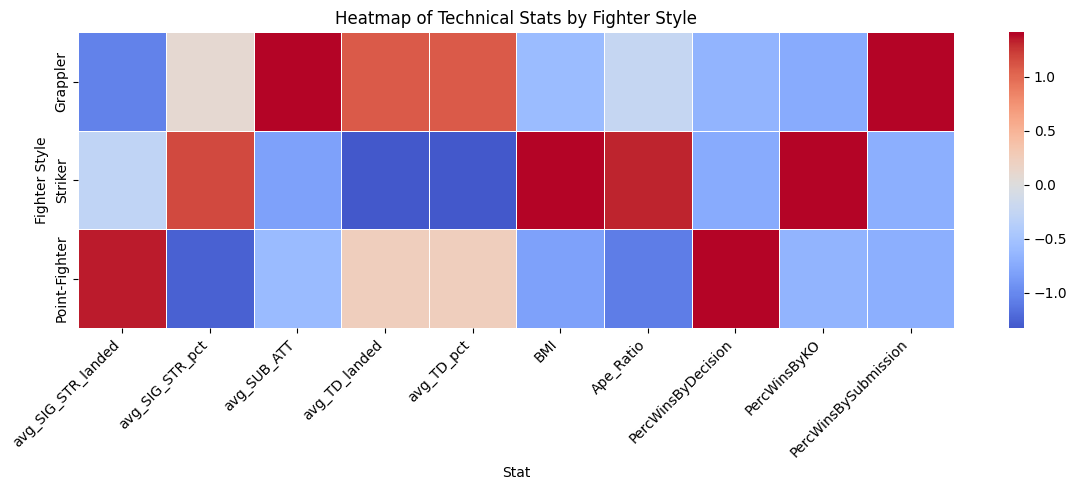

In [9]:
plt.figure(figsize=(12, 5))
sns.heatmap(style_summary_scaled, cmap="coolwarm", center=0, linewidths=0.5, annot=False)
plt.title("Heatmap of Technical Stats by Fighter Style")
plt.xlabel("Stat")
plt.ylabel("Fighter Style")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Fight Style Visualization

The clustering can also be visualized with PCA. The first three principal components are used for a 3D scatter plot.

In [12]:
import plotly.express as px

# 3D PCA visualization
pca = PCA(n_components=3, random_state=RANDOM_STATE)
pca_components = pca.fit_transform(scaled_style_features)

pca_data = pd.DataFrame(
    pca_components,
    columns=["PC1", "PC2", "PC3"]
)

pca_data["fighter"] = fighter_style_stats["fighter"].values
pca_data["StyleCluster"] = fighter_style_stats["StyleCluster"].map(style_labels).values

fig = px.scatter_3d(
    pca_data,
    x="PC1",
    y="PC2",
    z="PC3",
    color="StyleCluster",
    hover_name="fighter",
    title="Fighter Style Clustering (3D PCA)"
)

fig.show()


# Loadings for PC1, PC2, and PC3
pca_for_loadings = PCA(n_components=3, random_state=RANDOM_STATE)
pca_for_loadings.fit(scaled_style_features)

loading_df = pd.DataFrame(
    pca_for_loadings.components_.T,
    index=style_feature_cols,
    columns=["PC1", "PC2", "PC3"]
).reset_index(names="Feature")

display(loading_df)

,Feature,PC1,PC2,PC3
0,avg_SIG_STR_landed,-0.122829,0.282983,0.056428
1,avg_SIG_STR_pct,0.076363,-0.245325,0.412278
2,avg_SUB_ATT,0.451578,-0.210301,-0.208836
3,avg_TD_landed,0.455891,-0.011593,0.429838
4,avg_TD_pct,0.399080,-0.011282,0.435992
5,BMI,-0.175662,-0.257078,0.315750
6,Ape_Ratio,-0.027770,-0.186847,0.260793
7,PercWinsByDecision,0.052741,0.660734,0.202113
8,PercWinsByKO,-0.428236,-0.449950,0.150884
9,PercWinsBySubmission,0.436189,-0.274268,-0.420778


### PC1 Plot

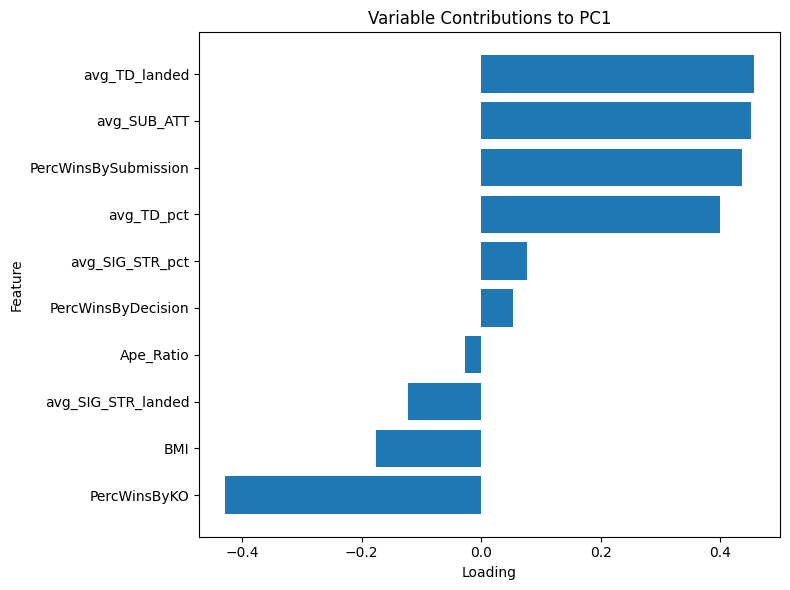

In [13]:
plot_df = loading_df.sort_values("PC1")

plt.figure(figsize=(8, 6))
plt.barh(plot_df["Feature"], plot_df["PC1"])
plt.title("Variable Contributions to PC1")
plt.xlabel("Loading")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

PC1 ranges from grappling-oriented fighters on one end to fighters with greater knockout power on the other end.

### PC2 Plot

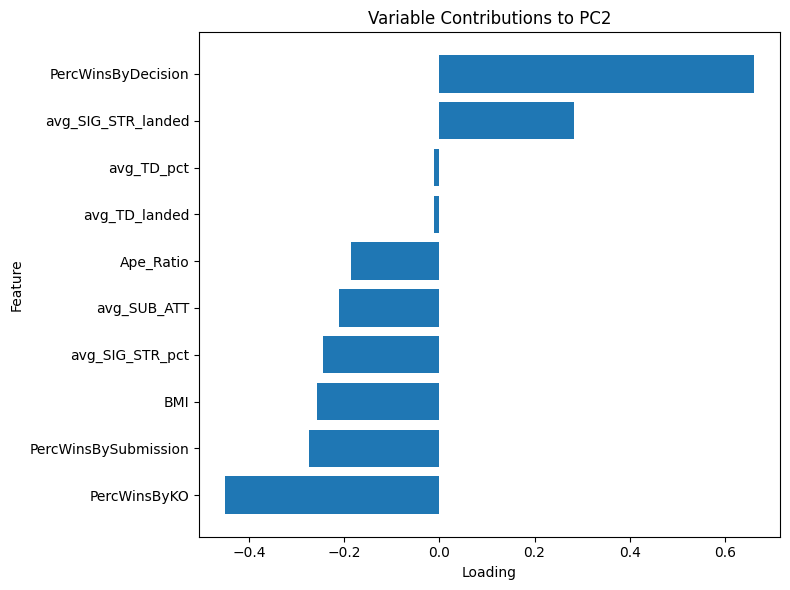

In [14]:
plot_df = loading_df.sort_values("PC2")

plt.figure(figsize=(8, 6))
plt.barh(plot_df["Feature"], plot_df["PC2"])
plt.title("Variable Contributions to PC2")
plt.xlabel("Loading")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

PC2 spans from point-fighters on one end to more aggressive finishers on the other end.

### PC3 Plot

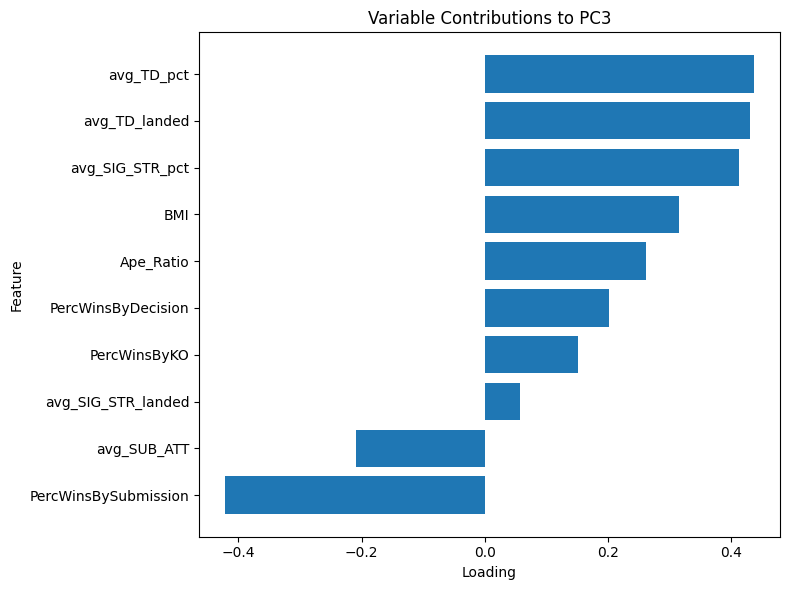

In [15]:
plot_df = loading_df.sort_values("PC3")

plt.figure(figsize=(8, 6))
plt.barh(plot_df["Feature"], plot_df["PC3"])
plt.title("Variable Contributions to PC3")
plt.xlabel("Loading")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

PC3 moves from submission-oriented fighters on one end to more efficient all-rounders on the other end.

## Elo Engine

The next engineered feature is an Elo rating. Every fighter starts at 1000, and ratings are updated chronologically after each fight.

In [22]:
# Sort ufc chronologically before calculating Elo
ufc["date"] = pd.to_datetime(ufc["date"], errors="coerce")
ufc = ufc.sort_values("date").reset_index(drop=True)

# Initialize Elo ratings
fighters = pd.unique(
    pd.concat([ufc["R_fighter"], ufc["B_fighter"]], ignore_index=True)
)

elo_ratings = {fighter: 1000.0 for fighter in fighters}

# Preallocate Elo columns directly in ufc
ufc["R_EloStart"] = 0.0
ufc["B_EloStart"] = 0.0
ufc["R_EloEnd"] = 0.0
ufc["B_EloEnd"] = 0.0


def expected_score(r1, r2):
    return 1 / (1 + 10 ** ((r2 - r1) / 400))


def update_elo(winner_elo, loser_elo, k=40):
    expected = expected_score(winner_elo, loser_elo)
    delta = k * (1 - expected)
    return winner_elo + delta, loser_elo - delta


for i, row in ufc.iterrows():
    red = row["R_fighter"]
    blue = row["B_fighter"]
    winner = row["Winner"]

    red_elo = elo_ratings[red]
    blue_elo = elo_ratings[blue]

    ufc.loc[i, "R_EloStart"] = red_elo
    ufc.loc[i, "B_EloStart"] = blue_elo

    if winner == "Red":
        red_new, blue_new = update_elo(red_elo, blue_elo)
        elo_ratings[red] = red_new
        elo_ratings[blue] = blue_new

    elif winner == "Blue":
        blue_new, red_new = update_elo(blue_elo, red_elo)
        elo_ratings[blue] = blue_new
        elo_ratings[red] = red_new

    ufc.loc[i, "R_EloEnd"] = elo_ratings[red]
    ufc.loc[i, "B_EloEnd"] = elo_ratings[blue]


elo_cols = ["R_EloStart", "B_EloStart", "R_EloEnd", "B_EloEnd"]
ufc[elo_cols] = ufc[elo_cols].round().astype(int)

display(
    ufc[
        [
            "Winner",
            "B_fighter",
            "R_fighter",
            "B_EloStart",
            "R_EloStart",
            "B_EloEnd",
            "R_EloEnd"
        ]
    ].tail(5)
)

,Winner,B_fighter,R_fighter,B_EloStart,R_EloStart,B_EloEnd,R_EloEnd
7164,Blue,Lerryan Douglas,Julian Erosa,1000,1045,1023,1022
7165,Red,Niko Price,Michael Chiesa,970,1123,958,1135
7166,Red,Maycee Barber,Alexa Grasso,1139,1070,1115,1094
7167,Red,Kyle Nelson,Terrance McKinney,1021,1030,1002,1049
7168,Blue,Joe Pyfer,Israel Adesanya,1096,1132,1118,1110


After creating the Elo engine, the individual blue and red variables are converted into blue-minus-red difference variables.

In [23]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from IPython.display import display

RANDOM_STATE = 123

# ------------------------------------------------------------
# 1. Start from ufc with Elo + style clusters already added
# ------------------------------------------------------------

ufc = ufc.loc[:, ~ufc.columns.duplicated()].copy()

required_columns = [
    "Winner",

    # Elo columns
    "R_EloStart",
    "B_EloStart",

    # Style cluster columns
    "R_StyleCluster",
    "B_StyleCluster",

    # Blue stats
    "B_draw",
    "B_wins",
    "B_current_lose_streak",
    "B_current_win_streak",
    "B_avg_SIG_STR_landed",
    "B_avg_SIG_STR_pct",
    "B_avg_SUB_ATT",
    "B_avg_TD_landed",
    "B_avg_TD_pct",
    "B_longest_win_streak",
    "B_losses",
    "B_total_rounds_fought",
    "B_total_title_bouts",
    "B_win_by_KO_TKO",
    "B_win_by_Submission",
    "B_win_by_Decision",
    "B_Height_cms",
    "B_Reach_cms",
    "B_Weight_lbs",
    "B_age",

    # Red stats
    "R_draw",
    "R_wins",
    "R_current_lose_streak",
    "R_current_win_streak",
    "R_avg_SIG_STR_landed",
    "R_avg_SIG_STR_pct",
    "R_avg_SUB_ATT",
    "R_avg_TD_landed",
    "R_avg_TD_pct",
    "R_longest_win_streak",
    "R_losses",
    "R_total_rounds_fought",
    "R_total_title_bouts",
    "R_win_by_KO_TKO",
    "R_win_by_Submission",
    "R_win_by_Decision",
    "R_Height_cms",
    "R_Reach_cms",
    "R_Weight_lbs",
    "R_age"
]

missing_columns = [col for col in required_columns if col not in ufc.columns]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")


# ------------------------------------------------------------
# 2. Engineer Blue - Red difference features
# ------------------------------------------------------------

ufc["EloDif"] = ufc["B_EloStart"] - ufc["R_EloStart"]

ufc["DrawDif"] = ufc["B_draw"] - ufc["R_draw"]
ufc["WinDif"] = ufc["B_wins"] - ufc["R_wins"]
ufc["CurrentLoseStreakDif"] = ufc["B_current_lose_streak"] - ufc["R_current_lose_streak"]
ufc["CurrentWinStreakDif"] = ufc["B_current_win_streak"] - ufc["R_current_win_streak"]
ufc["AvgSigStrLandedDif"] = ufc["B_avg_SIG_STR_landed"] - ufc["R_avg_SIG_STR_landed"]
ufc["AvgSigStrPctDif"] = ufc["B_avg_SIG_STR_pct"] - ufc["R_avg_SIG_STR_pct"]
ufc["AvgSubAttDif"] = ufc["B_avg_SUB_ATT"] - ufc["R_avg_SUB_ATT"]
ufc["AvgTDLandedDif"] = ufc["B_avg_TD_landed"] - ufc["R_avg_TD_landed"]
ufc["AvgTDPctDif"] = ufc["B_avg_TD_pct"] - ufc["R_avg_TD_pct"]
ufc["LongestWinStreakDif"] = ufc["B_longest_win_streak"] - ufc["R_longest_win_streak"]
ufc["LossDif"] = ufc["B_losses"] - ufc["R_losses"]
ufc["TotalRoundsFoughtDif"] = ufc["B_total_rounds_fought"] - ufc["R_total_rounds_fought"]
ufc["TotalTitleBoutDif"] = ufc["B_total_title_bouts"] - ufc["R_total_title_bouts"]
ufc["KODif"] = ufc["B_win_by_KO_TKO"] - ufc["R_win_by_KO_TKO"]
ufc["SubDif"] = ufc["B_win_by_Submission"] - ufc["R_win_by_Submission"]
ufc["DecDif"] = ufc["B_win_by_Decision"] - ufc["R_win_by_Decision"]
ufc["HeightDif"] = ufc["B_Height_cms"] - ufc["R_Height_cms"]
ufc["ReachDif"] = ufc["B_Reach_cms"] - ufc["R_Reach_cms"]
ufc["WeightDif"] = ufc["B_Weight_lbs"] - ufc["R_Weight_lbs"]
ufc["AgeDif"] = ufc["B_age"] - ufc["R_age"]


# ------------------------------------------------------------
# 3. Engineer style matchup feature
# ------------------------------------------------------------

ufc["R_StyleCluster"] = pd.to_numeric(ufc["R_StyleCluster"], errors="coerce")
ufc["B_StyleCluster"] = pd.to_numeric(ufc["B_StyleCluster"], errors="coerce")

ufc = ufc.dropna(subset=["R_StyleCluster", "B_StyleCluster"]).copy()

ufc["R_StyleCluster"] = ufc["R_StyleCluster"].astype(int)
ufc["B_StyleCluster"] = ufc["B_StyleCluster"].astype(int)

# Example: blue style 2 vs red style 1 becomes 21
ufc["StyleMatchup"] = (
    ufc["B_StyleCluster"] * 10 + ufc["R_StyleCluster"]
).astype(int)


# ------------------------------------------------------------
# 4. Drop raw columns after engineering
# ------------------------------------------------------------

columns_to_drop_after_engineering = [
    # Elo source columns
    "R_EloStart",
    "B_EloStart",

    # Post-fight Elo columns: leakage
    "R_EloEnd",
    "B_EloEnd",

    # Identifiers
    "date",
    "R_fighter",
    "B_fighter",

    # Blue source stats
    "B_current_lose_streak",
    "B_current_win_streak",
    "B_draw",
    "B_avg_SIG_STR_landed",
    "B_avg_SIG_STR_pct",
    "B_avg_SUB_ATT",
    "B_avg_TD_landed",
    "B_avg_TD_pct",
    "B_longest_win_streak",
    "B_losses",
    "B_total_rounds_fought",
    "B_total_title_bouts",
    "B_win_by_KO_TKO",
    "B_win_by_Submission",
    "B_wins",
    "B_Height_cms",
    "B_Reach_cms",
    "B_Weight_lbs",
    "B_age",
    "B_win_by_Decision",

    # Red source stats
    "R_current_lose_streak",
    "R_current_win_streak",
    "R_draw",
    "R_avg_SIG_STR_landed",
    "R_avg_SIG_STR_pct",
    "R_avg_SUB_ATT",
    "R_avg_TD_landed",
    "R_avg_TD_pct",
    "R_longest_win_streak",
    "R_losses",
    "R_total_rounds_fought",
    "R_total_title_bouts",
    "R_win_by_KO_TKO",
    "R_win_by_Submission",
    "R_wins",
    "R_Height_cms",
    "R_Reach_cms",
    "R_Weight_lbs",
    "R_age",
    "R_win_by_Decision",

    # Style source columns
    "R_StyleCluster",
    "B_StyleCluster",

    # Outcome/method column not used for Winner model
    "finish",

    # Fight context removed by your current setup
    "gender",
    "weight_class",
    "no_of_rounds",
    "title_bout",

    # Old raw difference columns, if still present
    "lose_streak_dif",
    "win_streak_dif",
    "longest_win_streak_dif",
    "win_dif",
    "loss_dif",
    "total_round_dif",
    "total_title_bout_dif",
    "ko_dif",
    "sub_dif",
    "height_dif",
    "reach_dif",
    "age_dif",
    "sig_str_dif",
    "avg_sub_att_dif",
    "avg_td_dif"
]

ufc_model = ufc.drop(
    columns=columns_to_drop_after_engineering,
    errors="ignore"
).copy()


# ------------------------------------------------------------
# 5. Prepare modeling dataset
# ------------------------------------------------------------

ufc_model = ufc_model[ufc_model["Winner"].isin(["Blue", "Red"])].copy()

ufc_model = ufc_model.dropna().copy()

ufc_model = ufc_model.loc[:, ~ufc_model.columns.duplicated()].copy()

min_class_count = ufc_model["Winner"].value_counts().min()

ufc_model = pd.concat(
    [
        group.sample(n=min_class_count, random_state=RANDOM_STATE)
        for _, group in ufc_model.groupby("Winner")
    ],
    axis=0
).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)


# ------------------------------------------------------------
# 6. Split predictors and target
# ------------------------------------------------------------

X = ufc_model.drop(columns=["Winner"]).copy()
y = ufc_model["Winner"].copy()

non_numeric_cols = X.select_dtypes(exclude=["number"]).columns.tolist()

if non_numeric_cols:
    X = pd.get_dummies(X, columns=non_numeric_cols, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Modeling data:", ufc_model.shape)
print("X:", X.shape)
print("Train:", X_train.shape, "Test:", X_test.shape)
display(y_train.value_counts())

Modeling data: (4872, 25)
X: (4872, 28)
Train: (3410, 28) Test: (1462, 28)


Winner
Red     1705
Blue    1705
Name: count, dtype: int64

## Modeling Helpers

These helper functions reproduce the tidymodels workflow behavior with scikit-learn pipelines: imputation, one-hot encoding, scaling, cross-validation, and metric calculation.

In [27]:
bool_cols = X_train.select_dtypes(include=["bool", "boolean"]).columns.tolist()

if bool_cols:
    X_train[bool_cols] = X_train[bool_cols].astype(float)
    X_test[bool_cols] = X_test[bool_cols].astype(float)

print("Boolean columns converted:", bool_cols)

def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_one_hot_encoder())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)


def roc_auc_blue(estimator, X_eval, y_eval):
    y_true = (pd.Series(y_eval).reset_index(drop=True) == "Blue").astype(int)

    probs = estimator.predict_proba(X_eval)
    class_list = list(estimator.classes_)
    blue_idx = class_list.index("Blue")

    return roc_auc_score(y_true, probs[:, blue_idx])


def evaluate_classifier(name, model, X_eval=X_test, y_eval=y_test, show_confusion=True):
    preds = model.predict(X_eval)
    probs = model.predict_proba(X_eval)

    blue_idx = list(model.classes_).index("Blue")
    blue_probs = probs[:, blue_idx]

    y_blue = (pd.Series(y_eval).reset_index(drop=True) == "Blue").astype(int)

    metrics = {
        "Model": name,
        "accuracy": accuracy_score(y_eval, preds),
        "roc_auc": roc_auc_score(y_blue, blue_probs)
    }

    if show_confusion:
        cm = confusion_matrix(y_eval, preds, labels=["Blue", "Red"])
        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Blue", "Red"]
        )
        disp.plot(values_format="d")
        plt.title(f"{name} Confusion Matrix")
        plt.show()

    return pd.DataFrame([metrics])


all_metrics = []

Boolean columns converted: ['R_Stance_Orthodox', 'R_Stance_Southpaw', 'R_Stance_Switch', 'B_Stance_Orthodox', 'B_Stance_Southpaw', 'B_Stance_Switch']


## K Nearest Neighbors

Best KNN parameters: {'model__n_neighbors': np.int64(25)}


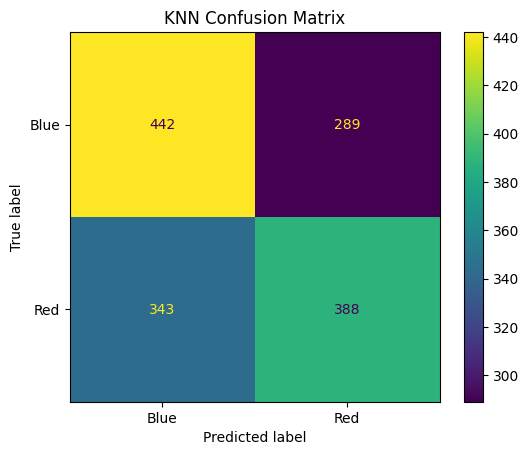

,Model,accuracy,roc_auc
0,KNN,0.567715,0.580091


In [29]:
knn_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", KNeighborsClassifier())
])

knn_param_grid = {
    "model__n_neighbors": np.unique(
        np.linspace(1, 25, 10).round().astype(int)
    )
}

knn_grid = GridSearchCV(
    knn_pipeline,
    param_grid=knn_param_grid,
    scoring=roc_auc_blue,
    cv=cv,
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)
knn_final = knn_grid.best_estimator_

print("Best KNN parameters:", knn_grid.best_params_)

knn_metrics = evaluate_classifier("KNN", knn_final)
all_metrics.append(knn_metrics)

display(knn_metrics)

KNN is a simple baseline model. In the original Rmd, it performed the worst among the tested models.

## Regularized Logistic Regression

Best Logistic Regression parameters: {'model__C': np.float64(0.021544346900318832), 'model__l1_ratio': np.float64(0.7777777777777777)}


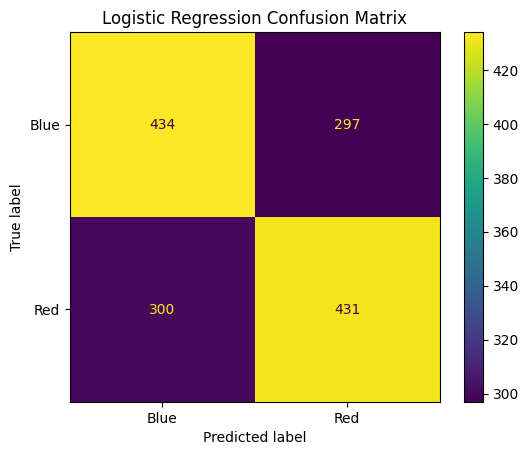

,Model,accuracy,roc_auc
0,Logistic Regression,0.591655,0.642468


In [30]:
log_reg_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

log_reg_param_grid = {
    "model__C": np.logspace(-3, 3, 10),
    "model__l1_ratio": np.linspace(0, 1, 10)
}

log_reg_grid = GridSearchCV(
    log_reg_pipeline,
    param_grid=log_reg_param_grid,
    scoring=roc_auc_blue,
    cv=cv,
    n_jobs=-1
)

log_reg_grid.fit(X_train, y_train)
log_reg_final = log_reg_grid.best_estimator_

print("Best Logistic Regression parameters:", log_reg_grid.best_params_)
log_reg_metrics = evaluate_classifier("Logistic Regression", log_reg_final)
all_metrics.append(log_reg_metrics)
display(log_reg_metrics)

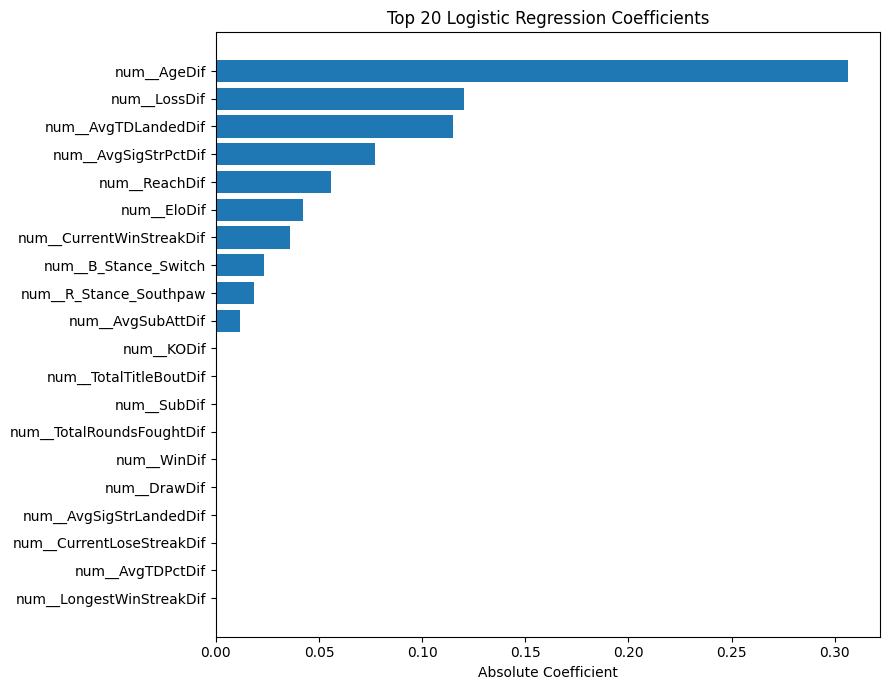

,term,estimate,abs_estimate
20,num__AgeDif,0.306659,0.306659
11,num__LossDif,0.120304,0.120304
8,num__AvgTDLandedDif,-0.114984,0.114984
6,num__AvgSigStrPctDif,-0.077242,0.077242
18,num__ReachDif,-0.055939,0.055939
0,num__EloDif,-0.042454,0.042454
4,num__CurrentWinStreakDif,-0.035776,0.035776
27,num__B_Stance_Switch,-0.023245,0.023245
23,num__R_Stance_Southpaw,0.018695,0.018695
7,num__AvgSubAttDif,-0.011531,0.011531


In [31]:
# Coefficient importance
feature_names = log_reg_final.named_steps["preprocess"].get_feature_names_out()
coef = log_reg_final.named_steps["model"].coef_[0]

log_reg_importance = pd.DataFrame({
    "term": feature_names,
    "estimate": coef,
    "abs_estimate": np.abs(coef)
}).sort_values("abs_estimate", ascending=False)

top_coef = log_reg_importance.head(20).sort_values("abs_estimate")

plt.figure(figsize=(9, 7))
plt.barh(top_coef["term"], top_coef["abs_estimate"])
plt.xlabel("Absolute Coefficient")
plt.ylabel("")
plt.title("Top 20 Logistic Regression Coefficients")
plt.tight_layout()
plt.show()

display(log_reg_importance.head(20))

Regularized logistic regression can shrink weak or noisy feature coefficients, making it useful for identifying which engineered variables have meaningful predictive influence.

## Random Forest

Best Random Forest parameters: {'model__max_features': 3, 'model__min_samples_leaf': 20, 'model__n_estimators': 200}


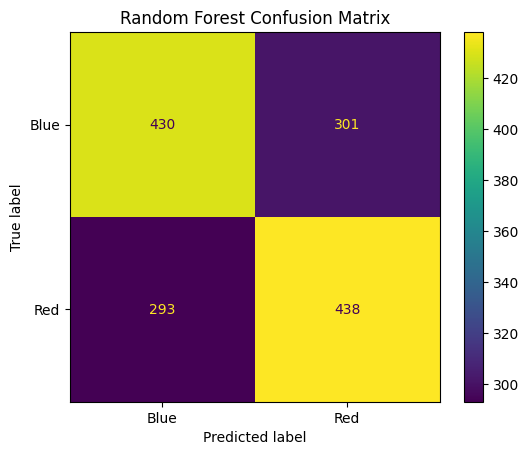

,Model,accuracy,roc_auc
0,Random Forest,0.593707,0.641679


In [32]:
rf_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight=None
    ))
])

rf_param_grid = {
    "model__max_features": [1, 2, 3, 4, 5, 6],
    "model__n_estimators": [200, 400, 600],
    "model__min_samples_leaf": [10, 15, 20]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    param_grid=rf_param_grid,
    scoring=roc_auc_blue,
    cv=cv,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)
rf_final = rf_grid.best_estimator_

print("Best Random Forest parameters:", rf_grid.best_params_)
rf_metrics = evaluate_classifier("Random Forest", rf_final)
all_metrics.append(rf_metrics)
display(rf_metrics)

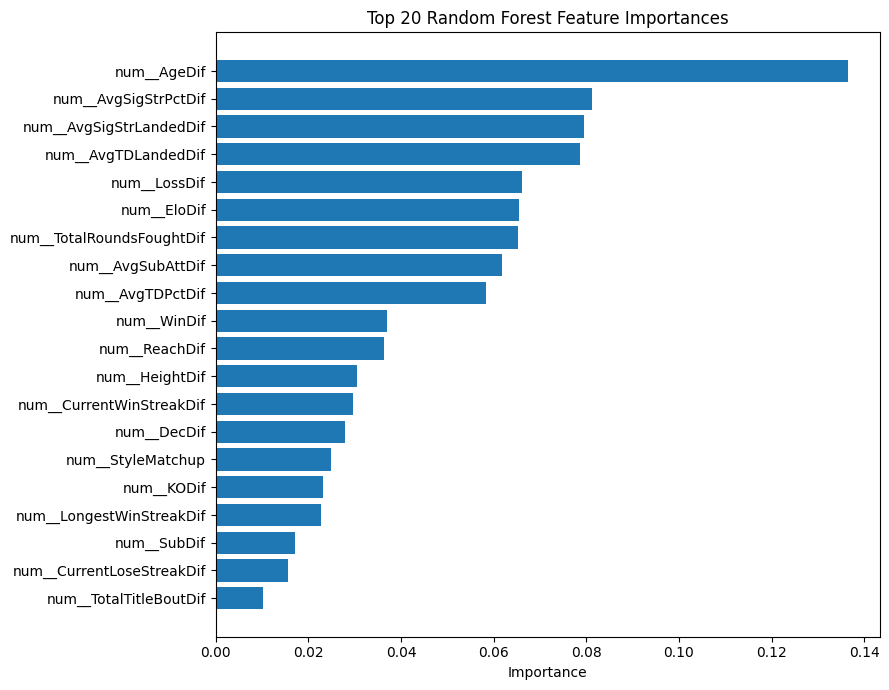

,feature,importance
20,num__AgeDif,0.136593
6,num__AvgSigStrPctDif,0.081182
5,num__AvgSigStrLandedDif,0.079488
8,num__AvgTDLandedDif,0.078613
11,num__LossDif,0.066098
0,num__EloDif,0.065508
12,num__TotalRoundsFoughtDif,0.065165
7,num__AvgSubAttDif,0.061752
9,num__AvgTDPctDif,0.058369
2,num__WinDif,0.036957


In [33]:
# Random Forest feature importance
rf_feature_names = rf_final.named_steps["preprocess"].get_feature_names_out()
rf_importance = pd.DataFrame({
    "feature": rf_feature_names,
    "importance": rf_final.named_steps["model"].feature_importances_
}).sort_values("importance", ascending=False)

top_rf = rf_importance.head(20).sort_values("importance")

plt.figure(figsize=(9, 7))
plt.barh(top_rf["feature"], top_rf["importance"])
plt.xlabel("Importance")
plt.ylabel("")
plt.title("Top 20 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

display(rf_importance.head(20))

Random Forest is a nonlinear model that can capture feature interactions and nonlinear relationships.

## XGBoost

This cell uses `xgboost` if it is installed. If not, it falls back to scikit-learn's `HistGradientBoostingClassifier` so the notebook can still run.

Best XGBoost parameters: {'model__learning_rate': np.float64(0.01), 'model__max_depth': 2, 'model__n_estimators': 400}


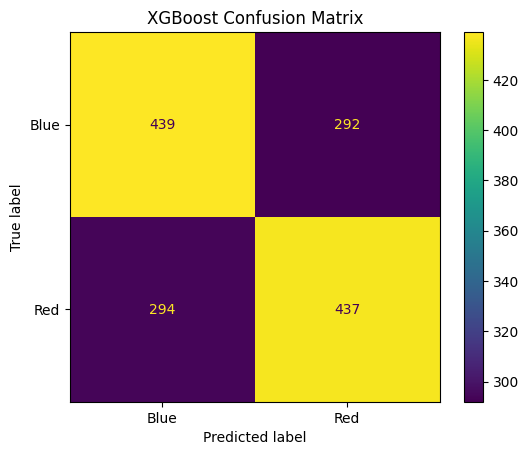

,Model,accuracy,roc_auc
0,XGBoost,0.599179,0.639338


In [34]:
try:
    from xgboost import XGBClassifier
    xgb_available = True
except ImportError:
    xgb_available = False

if xgb_available:
    xgb_model = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    xgb_pipeline = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", xgb_model)
    ])

    xgb_param_grid = {
        "model__max_depth": [2, 3, 4],
        "model__n_estimators": [200, 400, 600],
        "model__learning_rate": np.logspace(-3, -1, 5)
    }

    # XGBoost expects numeric target labels.
    y_train_xgb = y_train.map({"Red": 0, "Blue": 1})
    y_test_xgb = y_test.map({"Red": 0, "Blue": 1})

    def roc_auc_xgb(estimator, X_eval, y_eval):
        probs = estimator.predict_proba(X_eval)[:, 1]
        return roc_auc_score(y_eval, probs)

    xgb_grid = GridSearchCV(
        xgb_pipeline,
        param_grid=xgb_param_grid,
        scoring=roc_auc_xgb,
        cv=cv,
        n_jobs=-1
    )

    xgb_grid.fit(X_train, y_train_xgb)
    xgb_final = xgb_grid.best_estimator_
    print("Best XGBoost parameters:", xgb_grid.best_params_)

    xgb_pred_num = xgb_final.predict(X_test)
    xgb_prob_blue = xgb_final.predict_proba(X_test)[:, 1]
    xgb_pred_label = pd.Series(xgb_pred_num).map({0: "Red", 1: "Blue"})

    xgb_metrics = pd.DataFrame([{
        "Model": "XGBoost",
        "accuracy": accuracy_score(y_test, xgb_pred_label),
        "roc_auc": roc_auc_score(y_test_xgb, xgb_prob_blue)
    }])

    cm = confusion_matrix(y_test, xgb_pred_label, labels=["Blue", "Red"])
    ConfusionMatrixDisplay(cm, display_labels=["Blue", "Red"]).plot(values_format="d")
    plt.title("XGBoost Confusion Matrix")
    plt.show()

    all_metrics.append(xgb_metrics)
    display(xgb_metrics)

else:
    print("xgboost is not installed. Falling back to HistGradientBoostingClassifier.")

    hgb_pipeline = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))
    ])

    hgb_param_grid = {
        "model__learning_rate": np.logspace(-3, -1, 5),
        "model__max_iter": [200, 400, 600],
        "model__max_leaf_nodes": [15, 31, 63]
    }

    hgb_grid = GridSearchCV(
        hgb_pipeline,
        param_grid=hgb_param_grid,
        scoring=roc_auc_blue,
        cv=cv,
        n_jobs=-1
    )

    hgb_grid.fit(X_train, y_train)
    xgb_final = hgb_grid.best_estimator_
    print("Best Gradient Boosting parameters:", hgb_grid.best_params_)

    xgb_metrics = evaluate_classifier("Gradient Boosting", xgb_final)
    all_metrics.append(xgb_metrics)
    display(xgb_metrics)

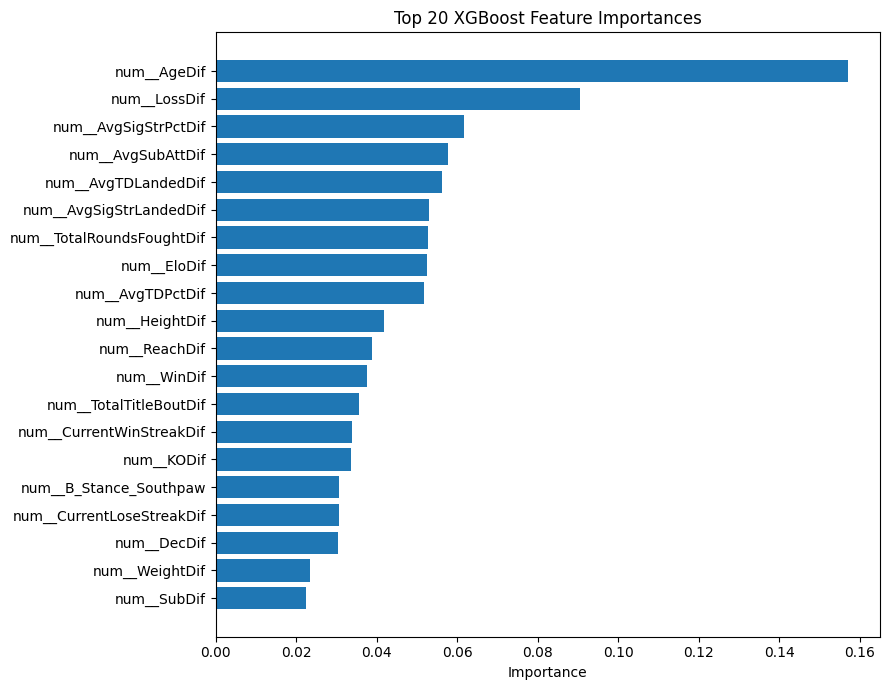

,feature,importance
20,num__AgeDif,0.157221
11,num__LossDif,0.090416
6,num__AvgSigStrPctDif,0.061798
7,num__AvgSubAttDif,0.057698
8,num__AvgTDLandedDif,0.056150
5,num__AvgSigStrLandedDif,0.052952
12,num__TotalRoundsFoughtDif,0.052745
0,num__EloDif,0.052518
9,num__AvgTDPctDif,0.051815
17,num__HeightDif,0.041751


In [35]:
# Feature importance for XGBoost when available
if xgb_available:
    xgb_feature_names = xgb_final.named_steps["preprocess"].get_feature_names_out()
    xgb_importance = pd.DataFrame({
        "feature": xgb_feature_names,
        "importance": xgb_final.named_steps["model"].feature_importances_
    }).sort_values("importance", ascending=False)

    top_xgb = xgb_importance.head(20).sort_values("importance")

    plt.figure(figsize=(9, 7))
    plt.barh(top_xgb["feature"], top_xgb["importance"])
    plt.xlabel("Importance")
    plt.ylabel("")
    plt.title("Top 20 XGBoost Feature Importances")
    plt.tight_layout()
    plt.show()

    display(xgb_importance.head(20))

XGBoost is an optimized boosting framework that can handle complex interactions and nonlinear patterns.

The original Rmd used a linear SVM after difficulty running the RBF version.

## Model Comparison

,Model,accuracy,roc_auc
0,KNN,0.567715,0.580091
1,KNN,0.567715,0.580091
2,Logistic Regression,0.591655,0.642468
3,Random Forest,0.593707,0.641679
4,XGBoost,0.599179,0.639338


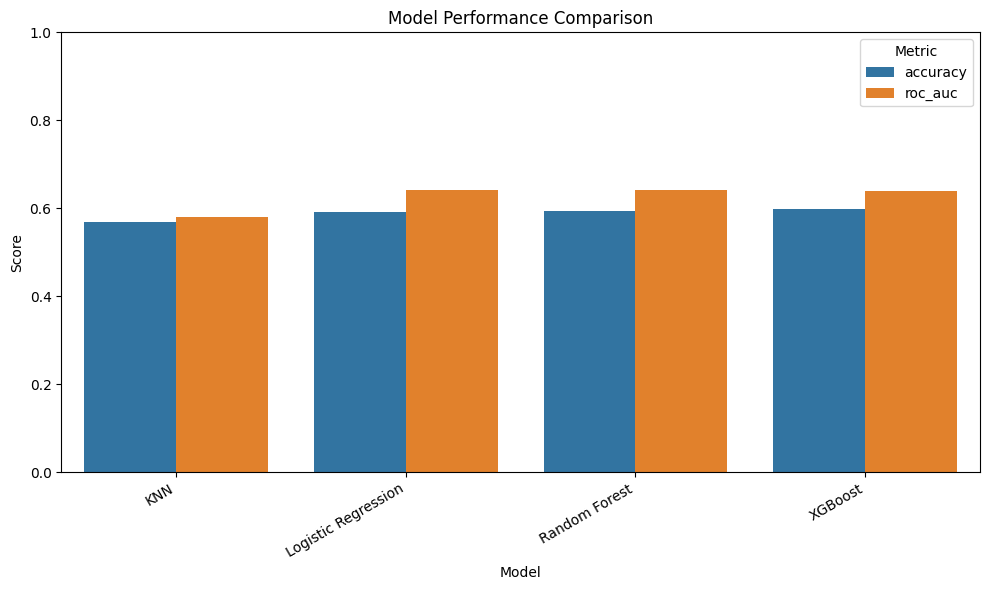

In [36]:
metrics_df = pd.concat(all_metrics, ignore_index=True)
display(metrics_df)

plot_data = metrics_df.melt(
    id_vars="Model",
    value_vars=["accuracy", "roc_auc"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))
sns.barplot(data=plot_data, x="Model", y="Score", hue="Metric")
plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

When comparing the models, KNN is expected to perform the worst due to its simplicity. The other models usually perform closer together, with modest predictive accuracy and somewhat stronger ROC AUC values.

## Conclusion

This workflow explored feature engineering for UFC prediction, including fighter style clustering and Elo ratings. The engineered features `EloDif` and `StyleMatchup` are designed to test whether fighter momentum and style matchups improve predictive performance.

Further improvements could include more systematic feature selection, PCA-based modeling, more detailed cluster validation, expanded hyperparameter tuning, and time-aware train/test splits.